In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv(
    'sales_data_sample.csv',
    encoding='unicode_escape'
)

print(df.head())

print("Dataset Shape:", df.shape)

print(df.info())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
print("Missing values:")
print(df.isnull().sum())

# Select numerical features
X = df[
    ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
]

# Handle missing values
X = X.fillna(X.mean())

print("Selected Features:")
print(X.head())

print("Shape:", X.shape)

Missing values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64
Selected Features:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95
Shape: (2823, 4)


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Normalized data:")
print(X_scaled[:5])

Normalized data:
[[-0.52289086  0.5969775  -0.37082523 -0.14224584]
 [-0.11220131 -0.11445035 -0.42789707 -0.14224584]
 [ 0.60650538  0.54938372  0.17944282 -0.14224584]
 [ 1.01719493 -0.01975856  0.10470098 -0.14224584]
 [ 1.42788447  0.81015797  0.89673966 -0.14224584]]


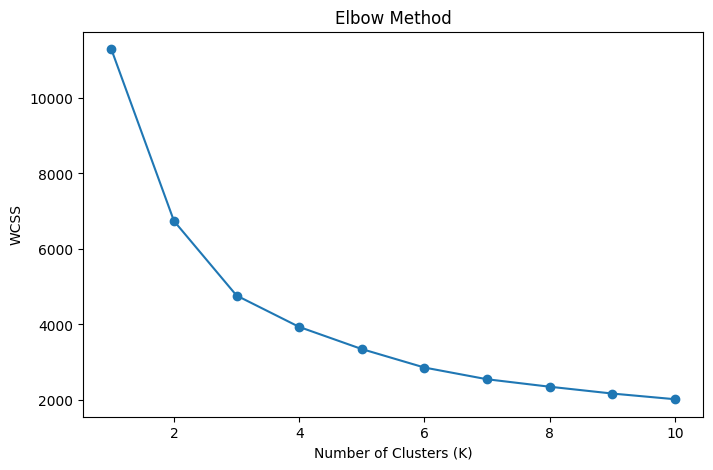

In [5]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method")

plt.xlabel("Number of Clusters (K)")

plt.ylabel("WCSS")

plt.show()

In [6]:
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

y_kmeans = kmeans.fit_predict(X_scaled)

df['KMeans_Cluster'] = y_kmeans

print("K-Means Cluster Labels:")
print(y_kmeans)

print("\nCluster Distribution:")
print(df['KMeans_Cluster'].value_counts())

K-Means Cluster Labels:
[2 2 1 ... 1 0 0]

Cluster Distribution:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


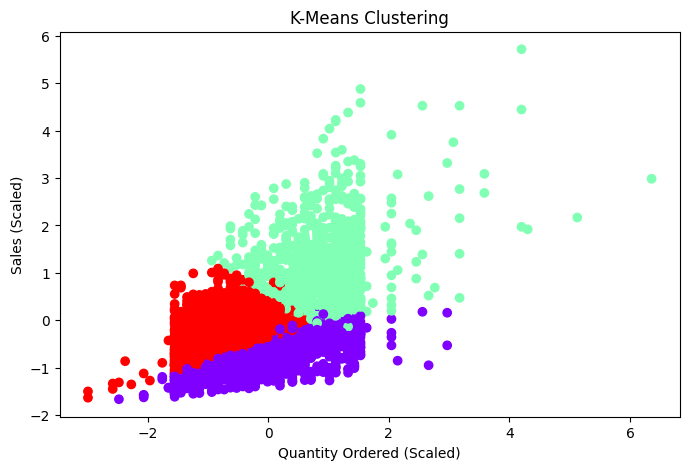

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=y_kmeans,
    cmap='rainbow'
)

plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")

plt.title("K-Means Clustering")

plt.show()

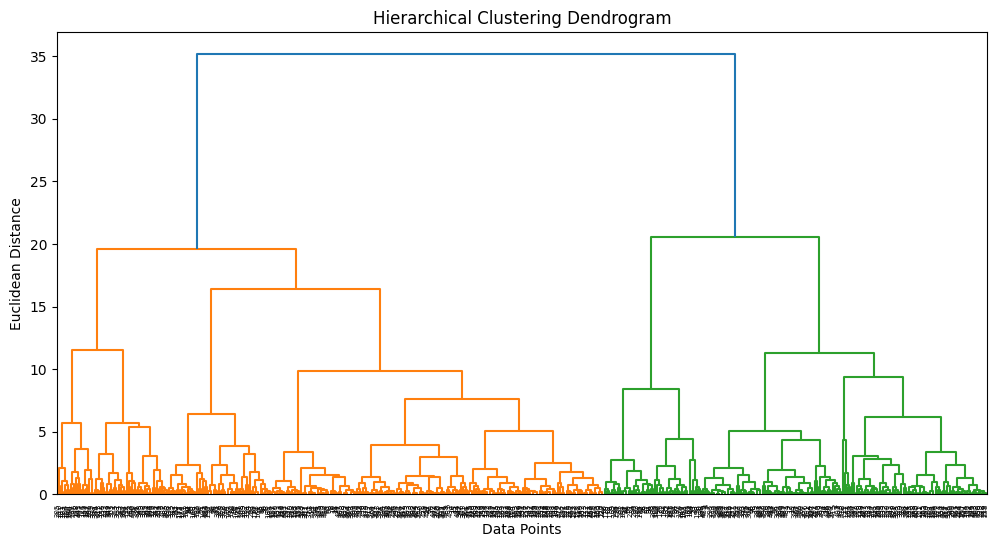

In [8]:
# Use a sample for a readable dendrogram
sample_data = X_scaled[:500]

linked = linkage(sample_data, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")

plt.xlabel("Data Points")

plt.ylabel("Euclidean Distance")

plt.show()

In [9]:
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

y_hc = hc.fit_predict(X_scaled)

df['Hierarchical_Cluster'] = y_hc

print("Hierarchical Cluster Labels:")
print(y_hc)

print("\nCluster Distribution:")
print(df['Hierarchical_Cluster'].value_counts())

Hierarchical Cluster Labels:
[2 2 0 ... 1 0 0]

Cluster Distribution:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


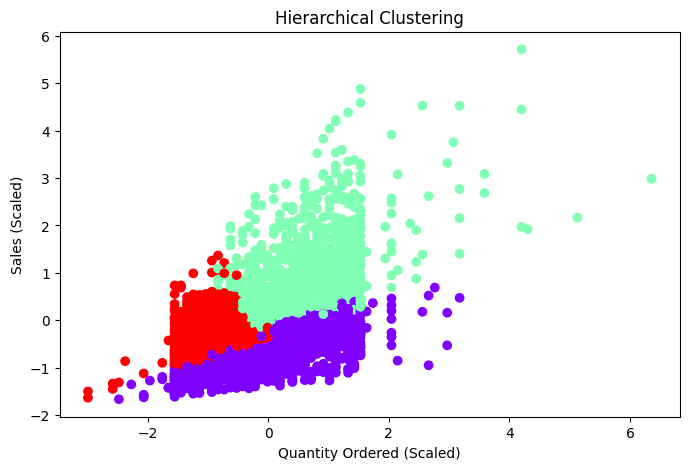

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=y_hc,
    cmap='rainbow'
)

plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")

plt.title("Hierarchical Clustering")

plt.show()

In [11]:
print("K-Means Cluster Distribution:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nHierarchical Cluster Distribution:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

print("\nCluster-wise Average Sales:")

print(
    df.groupby('KMeans_Cluster')[
        ['QUANTITYORDERED', 'SALES', 'PRICEEACH']
    ].mean()
)

K-Means Cluster Distribution:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64

Hierarchical Cluster Distribution:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64

Cluster-wise Average Sales:
                QUANTITYORDERED        SALES  PRICEEACH
KMeans_Cluster                                         
0                     35.208205  2101.076482  59.551169
1                     43.723005  5720.080669  97.479261
2                     27.597390  3123.062801  95.435090
